# Random Forest Classification — Effect of Tree Depth and Number of Trees
### ML Lab Experiment

**Aim:** To study how the hyperparameters of a Random Forest classifier — the **height (depth) of the trees** and the **number of trees** — affect its **Accuracy, Precision and Recall**.

**Steps in this notebook**
1. Load a sample dataset (Breast Cancer Wisconsin — built into scikit-learn, no download needed).
2. Train a Random Forest Classifier.
3. **(a)** Vary the height of the trees (`max_depth`) and observe the effect on Accuracy, Precision and Recall.
4. **(b)** Vary the number of tree instances (`n_estimators`) and observe the same effect.
5. Plot graphs comparing the results.
6. Print a final comparison table and pick the best configuration.

## Theory (short)

**Random Forest** is an *ensemble* learning method. It builds many decision trees on random subsets of the data (bootstrap sampling) and random subsets of features, then combines their predictions by **majority voting**.

| Hyperparameter | Meaning | Effect |
|---|---|---|
| `max_depth` | Maximum height of each tree | Too small → **underfitting**; too large → **overfitting** (trees memorise training data) |
| `n_estimators` | Number of trees in the forest | More trees → more stable / lower variance, with diminishing returns after a point |

**Metrics used** (for this dataset, class `1` = benign, `0` = malignant):

- **Accuracy** = (TP + TN) / (TP + TN + FP + FN) — overall fraction of correct predictions.
- **Precision** = TP / (TP + FP) — of all samples predicted positive, how many really are positive.
- **Recall** = TP / (TP + FN) — of all actual positives, how many were correctly found.

## Step 1 — Import Libraries

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Make plots look a bit nicer
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42   # fixed seed so results are reproducible
print("Libraries imported successfully.")

Libraries imported successfully.


In [16]:
#keeping the output clean

import warnings
warnings.filterwarnings("ignore")

## Step 2 — Load the Dataset

The **Breast Cancer Wisconsin (Diagnostic)** dataset has 569 samples and 30 numeric features computed from images of breast-mass cell nuclei. The task is to classify each tumour as **malignant (0)** or **benign (1)**.

In [17]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Shape of features :", X.shape)
print("Class names       :", list(data.target_names))
print("Class distribution:\n", y.value_counts().rename({0: 'malignant (0)', 1: 'benign (1)'}))
X.head()

Shape of features : (569, 30)
Class names       : [np.str_('malignant'), np.str_('benign')]
Class distribution:
 target
benign (1)       357
malignant (0)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Step 3 — Train / Test Split

We keep **70 %** of the data for training and **30 %** for testing. `stratify=y` keeps the class proportions the same in both sets.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 398
Testing samples : 171


## Step 4 — Baseline Random Forest

First, a Random Forest with default settings, just to see a starting point.

In [19]:
rf = RandomForestClassifier(random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("Baseline Random Forest (default parameters)")
print(f"  Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision : {precision_score(y_test, y_pred):.4f}")
print(f"  Recall    : {recall_score(y_test, y_pred):.4f}")

Baseline Random Forest (default parameters)
  Accuracy  : 0.9357
  Precision : 0.9444
  Recall    : 0.9533


## Helper Function

To avoid repeating code, this function trains a forest with given parameters and returns the metrics on **both the training and test sets**. Comparing the two helps us spot **overfitting**.

In [20]:
def evaluate_rf(max_depth=None, n_estimators=100):
    """Train a Random Forest and return train/test metrics as a dict."""
    model = RandomForestClassifier(
        max_depth=max_depth,
        n_estimators=n_estimators,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    model.fit(X_train, y_train)

    pred_test = model.predict(X_test)
    pred_train = model.predict(X_train)

    return {
        "Train Accuracy": accuracy_score(y_train, pred_train),
        "Accuracy":  accuracy_score(y_test, pred_test),
        "Precision": precision_score(y_test, pred_test),
        "Recall":    recall_score(y_test, pred_test),
    }

## Experiment (a) — Varying the Height of the Trees (`max_depth`)

We keep `n_estimators = 100` fixed and change `max_depth` from 1 to 15, plus `None` (unlimited depth).

In [21]:
depth_values = list(range(1, 16)) + [None]
depth_results = []

for d in depth_values:
    res = evaluate_rf(max_depth=d, n_estimators=100)
    res = {"max_depth": "None" if d is None else d, **res}
    depth_results.append(res)

depth_df = pd.DataFrame(depth_results)
depth_df.round(4)

,max_depth,Train Accuracy,Accuracy,Precision,Recall
0,1,0.9372,0.9064,0.9099,0.9439
1,2,0.9698,0.9298,0.9439,0.9439
2,3,0.9824,0.9357,0.9444,0.9533
3,4,0.9925,0.9415,0.9450,0.9626
4,5,0.9925,0.9415,0.9450,0.9626
5,6,0.9975,0.9357,0.9444,0.9533
6,7,0.9975,0.9357,0.9444,0.9533
7,8,1.0000,0.9357,0.9444,0.9533
8,9,1.0000,0.9357,0.9444,0.9533
9,10,1.0000,0.9357,0.9444,0.9533


### Plot — Effect of `max_depth` on Accuracy, Precision and Recall

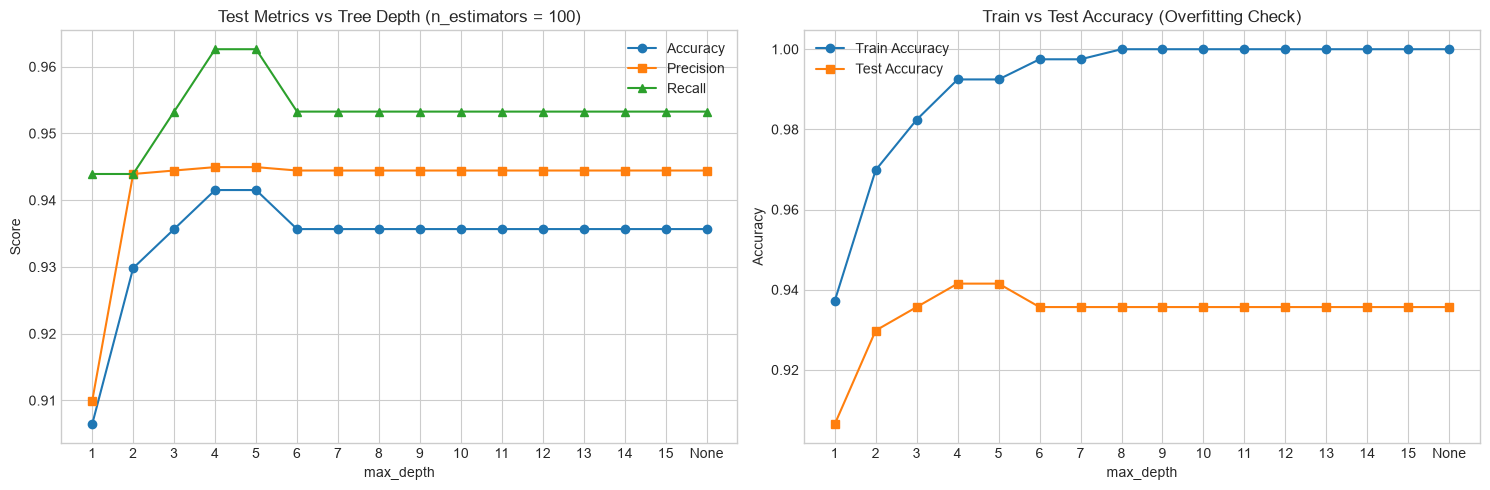

In [22]:
x_labels = depth_df["max_depth"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: test metrics
axes[0].plot(x_labels, depth_df["Accuracy"],  marker="o", label="Accuracy")
axes[0].plot(x_labels, depth_df["Precision"], marker="s", label="Precision")
axes[0].plot(x_labels, depth_df["Recall"],    marker="^", label="Recall")
axes[0].set_title("Test Metrics vs Tree Depth (n_estimators = 100)")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("Score")
axes[0].legend()

# Right: train vs test accuracy (overfitting check)
axes[1].plot(x_labels, depth_df["Train Accuracy"], marker="o", label="Train Accuracy")
axes[1].plot(x_labels, depth_df["Accuracy"],       marker="s", label="Test Accuracy")
axes[1].set_title("Train vs Test Accuracy (Overfitting Check)")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation (a):**
- With a very small depth (e.g. 1–2) the trees are too simple (*underfitting*), so all three metrics are lower.
- As depth increases, the metrics rise quickly and then **flatten out** — beyond a moderate depth, extra height adds almost no benefit.
- Train accuracy reaches ~100 % while test accuracy stays roughly constant, so very deep trees memorise training data without improving generalisation.

## Experiment (b) — Varying the Number of Trees (`n_estimators`)

Now we keep `max_depth = None` fixed and vary the number of trees.

In [23]:
tree_counts = [1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500]
tree_results = []

for n in tree_counts:
    res = evaluate_rf(max_depth=None, n_estimators=n)
    res = {"n_estimators": n, **res}
    tree_results.append(res)

tree_df = pd.DataFrame(tree_results)
tree_df.round(4)

,n_estimators,Train Accuracy,Accuracy,Precision,Recall
0,1,0.9774,0.9123,0.9340,0.9252
1,2,0.9724,0.8889,0.9583,0.8598
2,5,0.9899,0.9357,0.9444,0.9533
3,10,1.0000,0.9298,0.9524,0.9346
4,20,1.0000,0.9298,0.9439,0.9439
5,30,0.9975,0.9357,0.9444,0.9533
6,50,1.0000,0.9240,0.9434,0.9346
7,75,1.0000,0.9415,0.9450,0.9626
8,100,1.0000,0.9357,0.9444,0.9533
9,150,1.0000,0.9415,0.9450,0.9626


### Plot — Effect of `n_estimators` on Accuracy, Precision and Recall

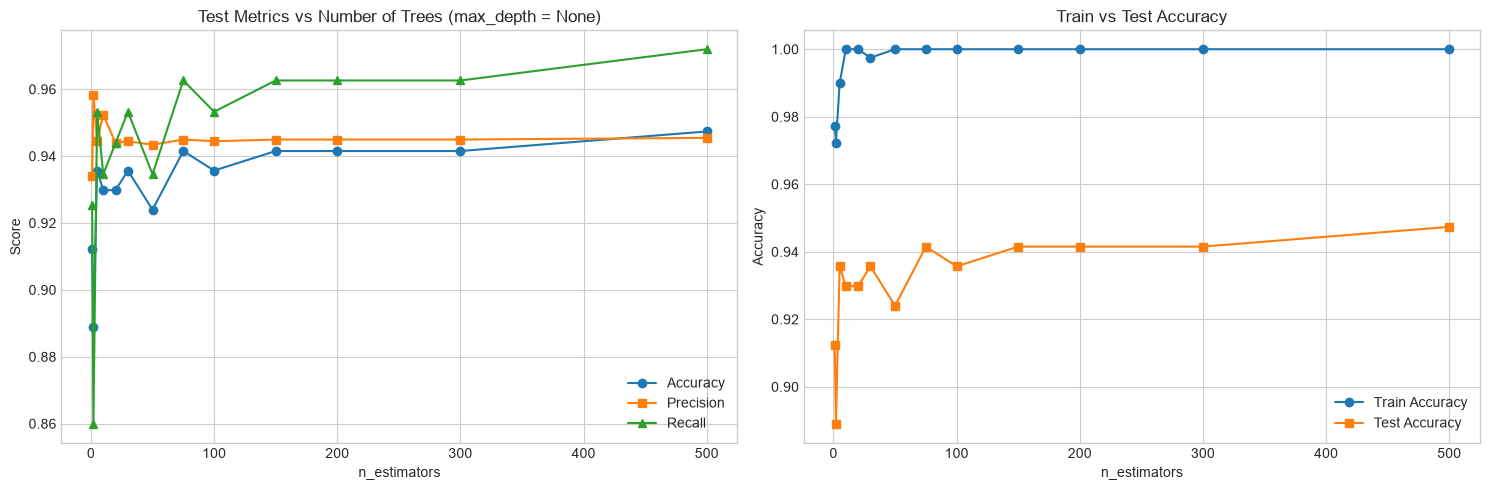

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(tree_df["n_estimators"], tree_df["Accuracy"],  marker="o", label="Accuracy")
axes[0].plot(tree_df["n_estimators"], tree_df["Precision"], marker="s", label="Precision")
axes[0].plot(tree_df["n_estimators"], tree_df["Recall"],    marker="^", label="Recall")
axes[0].set_title("Test Metrics vs Number of Trees (max_depth = None)")
axes[0].set_xlabel("n_estimators")
axes[0].set_ylabel("Score")
axes[0].legend()

axes[1].plot(tree_df["n_estimators"], tree_df["Train Accuracy"], marker="o", label="Train Accuracy")
axes[1].plot(tree_df["n_estimators"], tree_df["Accuracy"],       marker="s", label="Test Accuracy")
axes[1].set_title("Train vs Test Accuracy")
axes[1].set_xlabel("n_estimators")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation (b):**
- A single tree (`n_estimators = 1`) is basically a plain decision tree and is the least stable.
- Adding more trees quickly improves and **stabilises** the metrics because voting reduces variance.
- After roughly 50–100 trees the curves are nearly flat — more trees mainly cost extra computation with little gain.
- Unlike depth, adding trees does **not** cause overfitting; it only gives diminishing returns.

## Step 5 — Final Comparison Table and Best Configuration

We combine both experiments in a single table, then pick the best configuration. The best one is the one with the highest test **Accuracy**; ties are broken by **Precision**, then **Recall**. (Remaining ties are resolved in favour of the simpler model — the first row listed.)

In [25]:
depth_tbl = depth_df.copy()
depth_tbl.insert(0, "Experiment", "Vary max_depth")
depth_tbl["n_estimators"] = 100
depth_tbl = depth_tbl.rename(columns={"max_depth": "max_depth"})

tree_tbl = tree_df.copy()
tree_tbl.insert(0, "Experiment", "Vary n_estimators")
tree_tbl["max_depth"] = "None"

final_df = pd.concat([depth_tbl, tree_tbl], ignore_index=True)
final_df = final_df[["Experiment", "max_depth", "n_estimators",
                     "Train Accuracy", "Accuracy", "Precision", "Recall"]]

pd.set_option("display.max_rows", None)
final_df.round(4)

,Experiment,max_depth,n_estimators,Train Accuracy,Accuracy,Precision,Recall
0,Vary max_depth,1,100,0.9372,0.9064,0.9099,0.9439
1,Vary max_depth,2,100,0.9698,0.9298,0.9439,0.9439
2,Vary max_depth,3,100,0.9824,0.9357,0.9444,0.9533
3,Vary max_depth,4,100,0.9925,0.9415,0.9450,0.9626
4,Vary max_depth,5,100,0.9925,0.9415,0.9450,0.9626
5,Vary max_depth,6,100,0.9975,0.9357,0.9444,0.9533
6,Vary max_depth,7,100,0.9975,0.9357,0.9444,0.9533
7,Vary max_depth,8,100,1.0000,0.9357,0.9444,0.9533
8,Vary max_depth,9,100,1.0000,0.9357,0.9444,0.9533
9,Vary max_depth,10,100,1.0000,0.9357,0.9444,0.9533


In [26]:
best = final_df.sort_values(
    by=["Accuracy", "Precision", "Recall"], ascending=False, kind="stable"
).iloc[0]

print("=" * 50)
print("BEST CONFIGURATION")
print("=" * 50)
print(f"Experiment    : {best['Experiment']}")
print(f"max_depth     : {best['max_depth']}")
print(f"n_estimators  : {best['n_estimators']}")
print(f"Accuracy      : {best['Accuracy']:.4f}")
print(f"Precision     : {best['Precision']:.4f}")
print(f"Recall        : {best['Recall']:.4f}")

BEST CONFIGURATION
Experiment    : Vary n_estimators
max_depth     : None
n_estimators  : 500
Accuracy      : 0.9474
Precision     : 0.9455
Recall        : 0.9720


### Top 5 Configurations

In [27]:
final_df.sort_values(by=["Accuracy", "Precision", "Recall"],
                     ascending=False, kind="stable").head(5).round(4)

,Experiment,max_depth,n_estimators,Train Accuracy,Accuracy,Precision,Recall
28,Vary n_estimators,None,500,1.0000,0.9474,0.9455,0.9720
3,Vary max_depth,4,100,0.9925,0.9415,0.9450,0.9626
4,Vary max_depth,5,100,0.9925,0.9415,0.9450,0.9626
23,Vary n_estimators,None,75,1.0000,0.9415,0.9450,0.9626
25,Vary n_estimators,None,150,1.0000,0.9415,0.9450,0.9626


## Step 6 — Train the Final Model with the Best Configuration

Using the best parameters, we retrain and show the confusion matrix and classification report.

              precision    recall  f1-score   support

   malignant       0.95      0.91      0.93        64
      benign       0.95      0.97      0.96       107

    accuracy                           0.95       171
   macro avg       0.95      0.94      0.94       171
weighted avg       0.95      0.95      0.95       171



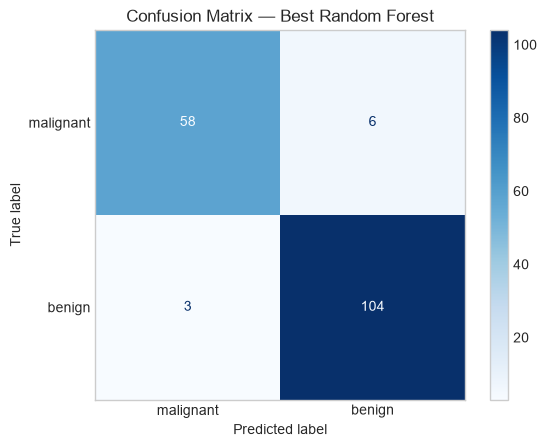

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

best_depth = None if str(best["max_depth"]) == "None" else int(best["max_depth"])
best_n = int(best["n_estimators"])

final_model = RandomForestClassifier(
    max_depth=best_depth, n_estimators=best_n, random_state=RANDOM_STATE, n_jobs=-1
)
final_model.fit(X_train, y_train)
y_final = final_model.predict(X_test)

print(classification_report(y_test, y_final, target_names=data.target_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_final),
                       display_labels=data.target_names).plot(cmap="Blues")
plt.title("Confusion Matrix — Best Random Forest")
plt.grid(False)
plt.show()

## Conclusion

1. **Tree depth (`max_depth`):** very shallow trees underfit and give poor Accuracy, Precision and Recall. Performance improves quickly with depth and then saturates; very deep trees reach ~100 % training accuracy without improving test performance (overfitting risk).
2. **Number of trees (`n_estimators`):** more trees make the model more stable and improve the metrics up to a point (about 50–100 trees here); beyond that the gain is negligible while training time increases.
3. A **moderate depth with a reasonably large number of trees** gives the best balance of Accuracy, Precision and Recall. The best configuration found is printed in Step 5.
4. For a medical problem like this one, **Recall** is especially important (missing a case is costly), so all three metrics should be examined together, not Accuracy alone.

*Note:* exact numbers may differ slightly if you change the random seed or the train/test split.